In [32]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


# WLadaLASSO (Konzen & Ziegelmann, 2016): full reproduction + FRED-MD extensions

**What this notebook does**

| Part | Content |
|---|---|
| 0 | Setup, configuration, caching |
| 1 | Estimation engine: LASSO, adaLASSO, WLadaLASSO (+ our extensions Ext1, Ext2) |
| 2-3 | Monte Carlo study (paper Tables I-IX, Figures 1-3) |
| 4 | Equity-premium application (paper Table X) on Goyal-Welch data |
| 5 | FRED-MD loader |
| 6 | Quarterly inflation application (paper Table XI analogue, built from FRED-MD) |
| 7-8 | **Our extensions on FRED-MD only**: data-driven lag profile (Ext1) and group-specific decay (Ext2) |

**Files you must download and place in a `data/` folder next to this notebook**

1. **FRED-MD** (landing page: https://www.stlouisfed.org/research/economists/mccracken/fred-databases)
   * `current.csv` (or a pinned monthly vintage such as `2026-02.csv`; rename it to `current.csv`)
     Direct link used by many packages:
     https://www.stlouisfed.org/-/media/project/frbstl/stlouisfed/research/fred-md/monthly/current.csv
   * The **appendix zip** from the same page; unzip it and keep `FRED-MD_updated_appendix.csv`
     (used only to get the 8 variable groups for Ext2; if missing, Ext2 falls back to own-lags vs other-variables).
2. **Goyal-Welch equity premium data**: Amit Goyal's website https://sites.google.com/view/agoyal145
   (the "Updated data" Excel file with Monthly / Quarterly / Annual sheets). Save as `data/PredictorData.xlsx`.

**Python packages**: `pip install numpy pandas scipy scikit-learn matplotlib joblib openpyxl`

**How progress is protected**: every expensive stage is cached to `results/*.pkl` through `cached(...)`.
If the kernel dies, re-run the notebook from the top and finished stages load instantly.
Change `FAST_MODE` to `False` for the paper-scale run (1000 Monte Carlo replications; this takes a long time).

In [45]:
import os, sys, time, pickle, warnings, math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.signal import lfilter
from sklearn.linear_model import lasso_path
from sklearn.isotonic import IsotonicRegression
from joblib import Parallel, delayed
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("/content/drive/MyDrive/data")
OUT_DIR = Path("results")
OUT_DIR.mkdir(exist_ok=True)

## Configuration
`FAST_MODE=True` gives a quick smoke run (few replications, fewer scenarios, coarser refitting).
Set it to `False` for the paper-scale experiments.

In [46]:
FAST_MODE = True          # <-- flip to False for the full paper-scale run
N_JOBS = -1               # joblib workers (-1 = all cores)
SEED = 20160221
TAG = "fast" if FAST_MODE else "full"

# ---- estimator settings (shared by all experiments unless overridden) ----
BASE_FIT = dict(
    gamma=1.0,                                   # adaLASSO exponent (paper: 1)
    n_lambda=100,                                # length of the lambda path
    eps=1e-3,                                    # lambda_min / lambda_max
    df_cap_frac=0.5,                             # ignore path points with df > 0.5 n (mimics glmnet early stopping)
    alphas=[0.0] + [float(a) for a in np.arange(0.5, 10.5, 0.5)],   # paper's alpha grid
    gammas=[0.5, 1.0, 1.5, 2.0],                 # used by 'adalasso_g' (ablation: gamma tuned by BIC)
    kappas=[0.0, 0.5, 1.0, 2.0, 3.0],            # Ext1 strength grid
    ext2_grid=[0.0, 0.25, 0.5, 1.0, 2.0],        # Ext2 per-group decay grid
    ext2_sweeps=1,
)

# ---- Monte Carlo (paper Section 'Simulation') ----
SIM = dict(
    n_rep=20 if FAST_MODE else 1000,
    T_list=[50, 500] if FAST_MODE else [50, 500, 2000],
    L_list=[5, 10, 20],
    rho_list=[0.3, 0.9] if FAST_MODE else [0.3, 0.6, 0.9],
    err_list=["normal"] if FAST_MODE else ["normal", "t5"],
    n_test=10,
    refit_every=5 if FAST_MODE else 1,           # paper re-estimates at every forecast origin
)

# ---- Equity premium (paper Table X) ----
EQ = dict(
    xlsx=DATA_DIR / "PredictorData.xlsx", sheet="Annual",
    start_year=1927, end_year=2005,
    log_premium=True,            # Goyal-Welch use log equity premium
    diff_predictors=True,        # paper: "differentiated and centered series" (set False to use levels)
    starts=(1955, 1970, 1985), Lmax=5,
)

# ---- FRED-MD ----
FRED = dict(
    csv=DATA_DIR / "current.csv",
    appendix=DATA_DIR / "FRED-MD_updated_appendix.csv",
    start="1960-03-01", end=None,
    target="CPIAUCSL",           # monthly inflation target for the extension study
    L=12,                        # candidate lags (monthly)
    n_test=60 if FAST_MODE else 180,
    refit_every=6 if FAST_MODE else 3,
)
FRED_FIT = dict(BASE_FIT,
                alphas=[0.0, 0.05, 0.1, 0.2, 0.35, 0.5],
                gammas=[0.5, 1.0, 2.0],
                kappas=[0.0, 0.5, 1.0, 2.0],
                ext2_grid=[0.0, 0.1, 0.2, 0.35, 0.5],
                n_lambda=60)

# ---- Quarterly inflation application (paper Table XI analogue) ----
INF = dict(price="PCEPI", end="2011-06-30", n_pred=16,
           Lgrid=[1, 2, 4, 8, 12, 16, 20] if not FAST_MODE else [1, 4, 8],
           period_len=20, refit_every=1 if not FAST_MODE else 4)

In [47]:
def cached(name, fn, force=False):
    """Run fn() once and pickle the result to results/<name>.pkl; reload on later runs."""
    f = OUT_DIR / f"{name}.pkl"
    if f.exists() and not force:
        with open(f, "rb") as fh:
            return pickle.load(fh)
    t0 = time.time()
    out = fn()
    with open(f, "wb") as fh:
        pickle.dump(out, fh)
    print(f"[cached] {name} done in {time.time() - t0:.1f}s")
    return out

print("FAST_MODE =", FAST_MODE, "| TAG =", TAG)

FAST_MODE = True | TAG = fast


# Part 1: Estimation engine

**Weighted LASSO via column rescaling.** The problem
$\min_\beta \|y-X\beta\|^2+\lambda\sum_j \omega_j|\beta_j|$ is solved by fitting an ordinary LASSO on
$\tilde X_j = X_j/\omega_j$ and mapping back with $\beta_j=\tilde\beta_j/\omega_j$ (exact).

**Weights.**
* adaLASSO: $\omega_j = |\hat\beta^{ridge}_j|^{-\gamma}$
* WLadaLASSO (paper): $\omega_j = |\hat\beta^{ridge}_j|^{-\gamma}\,e^{\alpha\, l_j}$, $\alpha$ chosen by BIC over $\{0,0.5,\dots,10\}$
* **Ext1 (ours)**: replace $e^{\alpha l}$ by a *data-driven* lag factor $\big(m(1)/m(l)\big)^{\kappa}$, where $m(\cdot)$ is a
  monotone-decreasing (isotonic) fit of mean $|\hat\beta^{ridge}|$ against lag; $\kappa$ chosen by BIC.
* **Ext2 (ours)**: variable-group-specific decay $e^{\alpha_{g(j)} l_j}$ (own lags + the 8 FRED-MD groups), $\alpha_g$ chosen by
  coordinate-wise BIC search starting from the best common $\alpha$.
* `adalasso_g`: ablation, adaLASSO with $\gamma$ also tuned by BIC (so that "WLadaLASSO wins" is not just "one more tuned parameter").

**Implementation notes (deviations/choices the paper leaves open)**
* Ridge first stage: penalty chosen by BIC through the SVD (works for $p>n$).
* BIC $=n\log(RSS/n)+df\log n$ with $df$ = number of non-zero coefficients.
* Path points with $df > 0.5\,n$ are discarded (glmnet stops its path early for the same reason; without this, BIC rewards interpolation when $p>n$).
* Log-weights are shifted so that the smallest is 0 and capped at 25 (avoids overflow of $e^{\alpha l}$; the shift is absorbed by $\lambda$).

In [48]:
LOGW_CAP = 25.0

def standardize(X, y):
    mu = X.mean(0)
    sd = X.std(0)
    sd[sd < 1e-12] = 1.0
    return (X - mu) / sd, y - y.mean(), mu, sd, y.mean()


def lag_matrix(D, L):
    """D: (T, M) with column 0 = target. Row r corresponds to time t = L + r (t = L..T, so the last
    row is the one-step-ahead regressor row). Columns ordered variable-major, lag-minor (lags 1..L)."""
    T, M = D.shape
    cols, lag_order, var_id = [], [], []
    for m in range(M):
        for l in range(1, L + 1):
            cols.append(D[L - l:T - l + 1, m])
            lag_order.append(l)
            var_id.append(m)
    return np.column_stack(cols), np.array(lag_order), np.array(var_id)


def ridge_bic(Xs, yc, df_cap_frac=0.5, n_grid=60):
    """Ridge coefficients with the penalty chosen by BIC (SVD; valid for p > n)."""
    n, p = Xs.shape
    U, S, Vt = np.linalg.svd(Xs, full_matrices=False)
    Uty = U.T @ yc
    best_bic, best_beta, fallback = np.inf, None, None
    for lam in S[0] ** 2 * np.logspace(-8, 1, n_grid):
        beta = Vt.T @ ((S / (S ** 2 + lam)) * Uty)
        df = float(np.sum(S ** 2 / (S ** 2 + lam)))
        fallback = beta
        if df > df_cap_frac * n:
            continue
        rss = float(np.sum((yc - Xs @ beta) ** 2))
        bic = n * np.log(rss / n + 1e-12) + df * np.log(n)
        if bic < best_bic:
            best_bic, best_beta = bic, beta
    return best_beta if best_beta is not None else fallback


def _wl_path(Xs, yc, log_w, n_lambda=100, eps=1e-3, df_cap=None):
    """Weighted LASSO path via rescaling; returns the BIC-optimal point."""
    n, p = Xs.shape
    lw = np.minimum(np.asarray(log_w, float) - np.min(log_w), LOGW_CAP)
    w = np.exp(lw)
    lams, coefs, _ = lasso_path(Xs / w, yc, eps=eps, n_alphas=n_lambda)
    betas = coefs / w[:, None]
    rss = ((yc[:, None] - Xs @ betas) ** 2).sum(0)
    df = (betas != 0).sum(0)
    bic = n * np.log(rss / n + 1e-12) + df * np.log(n)
    if df_cap is not None:
        bic = np.where(df > df_cap, np.inf, bic)
    k = int(np.argmin(bic))
    return dict(bic=float(bic[k]), beta=betas[:, k], lam=float(lams[k]), df=int(df[k]))


def isotonic_profile(b, lag_order, L):
    """Decreasing (isotonic) fit of mean |ridge coef| against lag l = 1..L."""
    lags = np.arange(1, L + 1)
    m = np.array([np.mean(np.abs(b[lag_order == l])) for l in lags])
    m = IsotonicRegression(increasing=False).fit_transform(lags, m)
    return np.maximum(m, 1e-6 * m.max() + 1e-12)


METHODS_ALL = ["lasso", "adalasso", "adalasso_g", "wladalasso", "ext1", "ext2"]

def fit_std(method, Xs, yc, lag_order, col_groups=None, cfg=None):
    """Fit on standardised data. Returns dict(beta, bic, df, hyper)."""
    cfg = dict(BASE_FIT, **(cfg or {}))
    n, p = Xs.shape
    kw = dict(n_lambda=cfg["n_lambda"], eps=cfg["eps"], df_cap=cfg["df_cap_frac"] * n)

    if method == "lasso":
        r = _wl_path(Xs, yc, np.zeros(p), **kw)
        r["hyper"] = {}
        return r

    b = ridge_bic(Xs, yc, cfg["df_cap_frac"])
    base = -np.log(np.abs(b) + 1e-8)            # log of 1/|b_ridge|
    L = int(lag_order.max())

    def best_of(cands):
        best = None
        for hyper, lw in cands:
            r = _wl_path(Xs, yc, lw, **kw)
            r["hyper"] = hyper
            if best is None or r["bic"] < best["bic"]:
                best = r
        return best

    if method == "adalasso":
        return best_of([({"gamma": cfg["gamma"]}, cfg["gamma"] * base)])
    if method == "adalasso_g":
        return best_of([({"gamma": g}, g * base) for g in cfg["gammas"]])
    if method == "wladalasso":
        return best_of([({"alpha": a}, cfg["gamma"] * base + a * lag_order) for a in cfg["alphas"]])
    if method == "ext1":
        m = isotonic_profile(b, lag_order, L)
        lag_pen = np.log(m[0]) - np.log(m[lag_order - 1])      # >= 0, increasing in lag
        r = best_of([({"kappa": k}, cfg["gamma"] * base + k * lag_pen) for k in cfg["kappas"]])
        r["hyper"]["profile"] = m / m[0]
        return r
    if method == "ext2":
        if col_groups is None:
            col_groups = np.zeros(p, dtype=int)
        G = int(col_groups.max()) + 1
        # step 1: best common alpha
        cur, a0 = None, 0.0
        for a in cfg["alphas"]:
            r = _wl_path(Xs, yc, cfg["gamma"] * base + a * lag_order, **kw)
            if cur is None or r["bic"] < cur["bic"]:
                cur, a0 = r, a
        alphas = np.full(G, a0)
        # step 2: coordinate-wise search over group-specific alphas
        for _ in range(cfg["ext2_sweeps"]):
            for g in range(G):
                if not np.any(col_groups == g):
                    continue
                for a in cfg["ext2_grid"]:
                    if a == alphas[g]:
                        continue
                    trial = alphas.copy()
                    trial[g] = a
                    r = _wl_path(Xs, yc, cfg["gamma"] * base + trial[col_groups] * lag_order, **kw)
                    if r["bic"] < cur["bic"] - 1e-9:
                        cur, alphas = r, trial
        cur["hyper"] = {"alphas": alphas, "alpha_common": a0}
        return cur
    raise ValueError(method)


def fit_raw(method, Z, y, lag_order, col_groups=None, cfg=None):
    """Fit on raw data (centres/scales internally; intercept recovered afterwards)."""
    Xs, yc, mu, sd, ym = standardize(Z, y)
    r = fit_std(method, Xs, yc, lag_order, col_groups, cfg)
    coef = r["beta"] / sd
    r["coef"] = coef
    r["intercept"] = float(ym - mu @ coef)
    return r

## Rolling (recursive) one-step-ahead forecasting
Origins are refit with an expanding window. `Lgrid` with more than one value implements the paper's
"number of lags optimised by BIC" (all candidate L share the same training sample, so BIC is comparable).

In [49]:
def make_designs(D, Lgrid, drop_own=False):
    designs = {}
    for L in Lgrid:
        Z, lag_order, var_id = lag_matrix(D, L)
        if drop_own:
            keep = var_id != 0
            Z, lag_order, var_id = Z[:, keep], lag_order[keep], var_id[keep]
        designs[L] = (Z, lag_order, var_id)
    return designs


def rolling_forecast(D, test_idx, method, Lgrid, t0=None, refit_every=1, var_groups=None,
                     cfg=None, n_jobs=1, drop_own=False):
    """One-step-ahead forecasts of D[t, 0] for t in test_idx using data up to t-1.
    D: (T, M) array, column 0 is the target. var_groups: group id per variable (length M)."""
    Lgrid = list(Lgrid)
    t0 = max(Lgrid) if t0 is None else t0
    designs = make_designs(D, Lgrid, drop_own)
    y = D[:, 0]
    test_idx = np.asarray(test_idx)
    fit_ts = list(test_idx[::refit_every])

    def one(t):
        best = None
        for L in Lgrid:
            Z, lag_order, var_id = designs[L]
            Ztr, ytr = Z[t0 - L:t - L], y[t0:t]
            cg = None if var_groups is None else np.asarray(var_groups)[var_id]
            r = fit_raw(method, Ztr, ytr, lag_order, cg, cfg)
            r["L"] = L
            if best is None or r["bic"] < best["bic"]:
                best = r
        return t, best

    if n_jobs == 1:
        res = [one(t) for t in fit_ts]
    else:
        res = Parallel(n_jobs=n_jobs)(delayed(one)(t) for t in fit_ts)
    fits = dict(res)

    pred = np.empty(len(test_idx))
    for i, t in enumerate(test_idx):
        ft = max(f for f in fit_ts if f <= t)
        fit = fits[ft]
        Z, lag_order, var_id = designs[fit["L"]]
        pred[i] = Z[t - fit["L"]] @ fit["coef"] + fit["intercept"]
    return dict(pred=pred, actual=y[test_idx], fits=fits, test_idx=test_idx,
                designs_meta={L: (designs[L][1], designs[L][2]) for L in Lgrid})


def ols_forecast(D, test_idx, cols, t_min=2):
    """Expanding-window OLS (with intercept) of y_t on x_{t-1}[cols]; used for Goyal-Welch style regressions."""
    y = D[:, 0]
    X = D[:, cols] if np.ndim(cols) else D[:, [cols]]
    out = []
    for t in test_idx:
        Xtr = np.column_stack([np.ones(t - 1), X[:t - 1]])
        beta = np.linalg.lstsq(Xtr, y[1:t], rcond=None)[0]
        out.append(np.r_[1.0, X[t - 1]] @ beta)
    return np.array(out)


def ar_forecasts(y, test_idx, pmax=12, t0=None):
    """AR(p) benchmark with p in 0..pmax chosen by BIC (p=0 is the historical mean), expanding window."""
    t0 = pmax if t0 is None else t0
    mats = {p: (lag_matrix(y[:, None], p)[0] if p > 0 else None) for p in range(0, pmax + 1)}
    out = []
    for t in test_idx:
        best = (np.inf, None)
        n = t - t0
        for p in range(0, pmax + 1):
            if p == 0:
                Xtr, xnew = np.ones((n, 1)), np.ones(1)
            else:
                Z = mats[p]
                Xtr = np.column_stack([np.ones(n), Z[t0 - p:t - p]])
                xnew = np.r_[1.0, Z[t - p]]
            ytr = y[t0:t]
            beta = np.linalg.lstsq(Xtr, ytr, rcond=None)[0]
            rss = np.sum((ytr - Xtr @ beta) ** 2)
            bic = n * np.log(rss / n + 1e-12) + (p + 1) * np.log(n)
            if bic < best[0]:
                best = (bic, xnew @ beta)
        out.append(best[1])
    return np.array(out)

## Evaluation helpers: out-of-sample $R^2$ and the modified Diebold-Mariano test (Harvey et al., 1997)

In [50]:
def r2_oos(actual, pred, bench):
    return 1.0 - np.sum((actual - pred) ** 2) / np.sum((actual - bench) ** 2)


def mdm_test(loss_bench, loss_model, h=1):
    """One-sided modified DM test. H1: the model has smaller expected loss than the benchmark.
    Returns (statistic, p-value)."""
    d = np.asarray(loss_bench) - np.asarray(loss_model)
    n = len(d)
    dbar = d.mean()
    gam = [np.mean((d[k:] - dbar) * (d[:n - k] - dbar)) for k in range(h)]
    var = (gam[0] + 2 * sum(gam[1:])) / n
    if var <= 0:
        return np.nan, np.nan
    dm = dbar / np.sqrt(var)
    mdm = dm * np.sqrt((n + 1 - 2 * h + h * (h - 1) / n) / n)
    return float(mdm), float(1 - stats.t.cdf(mdm, df=n - 1))

# Part 2: Monte Carlo study (paper Section 'Simulation')

DGP (paper eq. 10), with 10 independent AR(1) predictors $x_{i,t}=\rho x_{i,t-1}+u_{i,t}$:

$y_t = 0.8y_{t-1}+0.6x_{1,t-1}+0.3x_{1,t-2}-0.5x_{2,t-1}-0.2x_{2,t-2}+0.4x_{3,t-1}+0.3x_{3,t-2}+0.4x_{4,t-1}-0.3x_{5,t-1}+0.2x_{6,t-1}+\varepsilon_t$

Errors $\varepsilon_t$ and $u_{i,t}$ are N(0,1) or t(5). Candidates: $L$ lags of $y$ and of each $x_j$ ($11L$ regressors), $L\in\{5,10,20\}$.
The last 10 observations are held out and forecast one step ahead with re-estimation at every origin.
We simulate $L$ extra pre-sample points so that the effective training size is $T-10$ regardless of $L$.

Selection metrics (paper): FVCI, TMI, FRVI, FIVE, NIV. Estimation metrics: MSE/MAE of the coefficient vector (eqs. 11-12).
Forecast metrics: mean/median over replications of the MSE and MAE of the 10 forecast errors.

Selection and estimation metrics are computed from the first fit (training sample = first $T-10$ observations).

In [51]:
SIM_METHODS = ["lasso", "adalasso", "wladalasso"]

def draw_noise(rng, err, size):
    return rng.standard_normal(size) if err == "normal" else rng.standard_t(5, size)


def simulate_data(T, L, rho, err, rng, burn=100):
    """Returns D of shape (T + L, 11): column 0 = y, columns 1..10 = x1..x10."""
    n = T + L + burn
    K = 10
    u = draw_noise(rng, err, (n, K))
    eps = draw_noise(rng, err, n)
    x = lfilter([1.0], [1.0, -rho], u, axis=0)
    y = np.zeros(n)
    for t in range(2, n):
        y[t] = (0.8 * y[t - 1]
                + 0.6 * x[t - 1, 0] + 0.3 * x[t - 2, 0]
                - 0.5 * x[t - 1, 1] - 0.2 * x[t - 2, 1]
                + 0.4 * x[t - 1, 2] + 0.3 * x[t - 2, 2]
                + 0.4 * x[t - 1, 3]
                - 0.3 * x[t - 1, 4]
                + 0.2 * x[t - 1, 5]
                + eps[t])
    return np.column_stack([y, x])[burn:]


def true_beta(L, K=10):
    B = np.zeros((K + 1, L))
    B[0, 0] = 0.8
    B[1, 0], B[1, 1] = 0.6, 0.3
    B[2, 0], B[2, 1] = -0.5, -0.2
    B[3, 0], B[3, 1] = 0.4, 0.3
    B[4, 0] = 0.4
    B[5, 0] = -0.3
    B[6, 0] = 0.2
    return B.ravel()          # variable-major, lag-minor: same as lag_matrix


def selection_metrics(b_hat, b_true):
    sel, rel = b_hat != 0, b_true != 0
    return dict(FVCI=float(np.mean(sel == rel)),
                TMI=float(sel[rel].all()),
                FRVI=float(sel[rel].mean()),
                FIVE=float((~sel[~rel]).mean()),
                NIV=float(sel.sum()))


def sim_one(seed_seq, T, L, rho, err, n_test, refit_every, cfg):
    rng = np.random.default_rng(seed_seq)
    D = simulate_data(T, L, rho, err, rng)
    test_idx = np.arange(len(D) - n_test, len(D))
    b_true = true_beta(L)
    out = {}
    for m in SIM_METHODS:
        fc = rolling_forecast(D, test_idx, m, [L], t0=L, refit_every=refit_every, cfg=cfg)
        b = fc["fits"][test_idx[0]]["coef"]
        out[m] = dict(sel=selection_metrics(b, b_true),
                      coef_mse=float(np.mean((b - b_true) ** 2)),
                      coef_mae=float(np.mean(np.abs(b - b_true))),
                      err=fc["actual"] - fc["pred"],
                      alpha=fc["fits"][test_idx[0]]["hyper"].get("alpha", np.nan))
    return out


def run_scenario(T, L, rho, err, scen_id):
    key = f"sim_{TAG}_{err}_rho{rho}_L{L}_T{T}"
    seeds = np.random.SeedSequence([SEED, scen_id]).spawn(SIM["n_rep"])

    def work():
        return Parallel(n_jobs=N_JOBS)(
            delayed(sim_one)(s, T, L, rho, err, SIM["n_test"], SIM["refit_every"], BASE_FIT) for s in seeds)
    return cached(key, work)


def summarise(reps):
    rows = []
    for m in SIM_METHODS:
        sel = pd.DataFrame([r[m]["sel"] for r in reps]).mean().to_dict()
        errs = np.array([r[m]["err"] for r in reps])
        mse, mae = (errs ** 2).mean(1), np.abs(errs).mean(1)
        rows.append(dict(method=m, **sel,
                         coef_MSE=np.mean([r[m]["coef_mse"] for r in reps]),
                         coef_MAE=np.mean([r[m]["coef_mae"] for r in reps]),
                         fc_MSE_mean=mse.mean(), fc_MSE_median=np.median(mse),
                         fc_MAE_mean=mae.mean(), fc_MAE_median=np.median(mae)))
    return pd.DataFrame(rows)

# Part 3: Run the Monte Carlo and build the paper's tables and figures
Each scenario (error law x rho x L x T) is cached separately in `results/`, so an interrupted run resumes where it stopped.
Rough cost guide: `FAST_MODE=True` finishes in minutes on a laptop; the full run (1000 reps, 54 scenarios, 21 alphas) takes many hours.

In [52]:
all_summ, all_reps = [], {}
scen_id = 0
t_start = time.time()
for err in SIM["err_list"]:
    for rho in SIM["rho_list"]:
        for L in SIM["L_list"]:
            for T in SIM["T_list"]:
                scen_id += 1
                reps = run_scenario(T, L, rho, err, scen_id)
                all_reps[(err, rho, L, T)] = reps
                s = summarise(reps)
                s["err"], s["rho"], s["L"], s["T"] = err, rho, L, T
                all_summ.append(s)
                print(f"done {err} rho={rho} L={L} T={T}  ({time.time() - t_start:.0f}s elapsed)")
SUMM = pd.concat(all_summ, ignore_index=True)
SUMM.to_csv(OUT_DIR / f"simulation_summary_{TAG}.csv", index=False)
SUMM.head()

done normal rho=0.3 L=5 T=50  (0s elapsed)
done normal rho=0.3 L=5 T=500  (0s elapsed)
done normal rho=0.3 L=10 T=50  (0s elapsed)
done normal rho=0.3 L=10 T=500  (0s elapsed)
done normal rho=0.3 L=20 T=50  (0s elapsed)
done normal rho=0.3 L=20 T=500  (0s elapsed)
done normal rho=0.9 L=5 T=50  (0s elapsed)
done normal rho=0.9 L=5 T=500  (0s elapsed)
done normal rho=0.9 L=10 T=50  (0s elapsed)
done normal rho=0.9 L=10 T=500  (0s elapsed)
done normal rho=0.9 L=20 T=50  (0s elapsed)
done normal rho=0.9 L=20 T=500  (0s elapsed)


,method,FVCI,TMI,FRVI,FIVE,NIV,coef_MSE,coef_MAE,fc_MSE_mean,fc_MSE_median,fc_MAE_mean,fc_MAE_median,err,rho,L,T
0,lasso,0.806364,0.0,0.545,0.864444,11.55,0.017495,0.058692,2.292086,2.078621,1.204110,1.154589,normal,0.3,5,50
1,adalasso,0.787273,0.0,0.505,0.850000,11.80,0.023915,0.072962,2.355576,2.136599,1.212240,1.153360,normal,0.3,5,50
2,wladalasso,0.820909,0.0,0.655,0.857778,12.95,0.021469,0.067083,2.142315,1.777252,1.145905,1.082035,normal,0.3,5,50
3,lasso,0.944545,1.0,1.000,0.932222,13.05,0.001179,0.013650,1.049491,0.889152,0.814721,0.757996,normal,0.3,5,500
4,adalasso,0.990000,1.0,1.000,0.987778,10.55,0.000665,0.008792,1.024737,0.860309,0.796340,0.743911,normal,0.3,5,500


## Tables I-III (model selection), IV-VI (parameter estimates), VII-IX (forecasts)
One table per $\rho$ (0.3 -> I/IV/VII, 0.6 -> II/V/VIII, 0.9 -> III/VI/IX). Columns are (candidate lags L, sample size T).

In [53]:
ROMAN = {0.3: ("I", "IV", "VII"), 0.6: ("II", "V", "VIII"), 0.9: ("III", "VI", "IX")}
PANELS = {
    "sel": ["FVCI", "TMI", "FRVI", "FIVE", "NIV"],
    "est": ["coef_MSE", "coef_MAE"],
    "fc":  ["fc_MSE_mean", "fc_MSE_median", "fc_MAE_mean", "fc_MAE_median"],
}

def show_table(kind, rho, err="normal", digits=4):
    sub = SUMM[(SUMM.rho == rho) & (SUMM.err == err)]
    if sub.empty:
        return
    idx = {"sel": 0, "est": 1, "fc": 2}[kind]
    print(f"\n=== Table {ROMAN[rho][idx]}  (rho = {rho}, errors = {err}) ===")
    for panel in PANELS[kind]:
        pv = sub.pivot_table(index="method", columns=["L", "T"], values=panel).reindex(SIM_METHODS)
        print(f"--- {panel}")
        display(pv.round(digits))

for rho in SIM["rho_list"]:
    for kind in ["sel", "est", "fc"]:
        show_table(kind, rho)


=== Table I  (rho = 0.3, errors = normal) ===
--- FVCI


L               5               10              20        
T              50      500     50      500     50      500
method                                                    
lasso       0.8064  0.9445  0.8968  0.9745  0.9402  0.9830
adalasso    0.7873  0.9900  0.8727  0.9905  0.9307  0.9891
wladalasso  0.8209  0.9964  0.9132  0.9973  0.9743  0.9980

--- TMI


L            5          10          20      
T           50    500  50    500   50    500
method                                      
lasso       0.0  1.00  0.0  1.00  0.00  0.95
adalasso    0.0  1.00  0.0  0.95  0.00  1.00
wladalasso  0.0  0.95  0.0  1.00  0.05  0.90

--- FRVI


L              5             10            20       
T             50     500    50     500    50     500
method                                              
lasso       0.545  1.000  0.410  1.000  0.460  0.995
adalasso    0.505  1.000  0.435  0.995  0.375  1.000
wladalasso  0.655  0.995  0.635  1.000  0.660  0.990

... (34 outputs left out)

--- fc_MAE_mean


L               5               10              20        
T              50      500     50      500     50      500
method                                                    
lasso       1.9368  0.8315  2.0475  0.8363  2.3335  0.9291
adalasso    1.9342  0.9737  2.0942  0.9228  2.3325  0.9061
wladalasso  1.5823  0.9738  1.5850  0.9275  1.8095  0.9100

--- fc_MAE_median


L               5               10              20        
T              50      500     50      500     50      500
method                                                    
lasso       1.8391  0.8055  2.0825  0.8270  2.2341  0.8993
adalasso    1.9192  0.9954  2.1795  0.9286  2.2744  0.8975
wladalasso  1.4927  0.9954  1.3101  0.9216  1.5716  0.9190

## Figures 1-3: distribution of one-step-ahead forecast errors
(3x3 grid per $\rho$: rows = candidate lags, columns = sample size; outliers hidden for readability.)

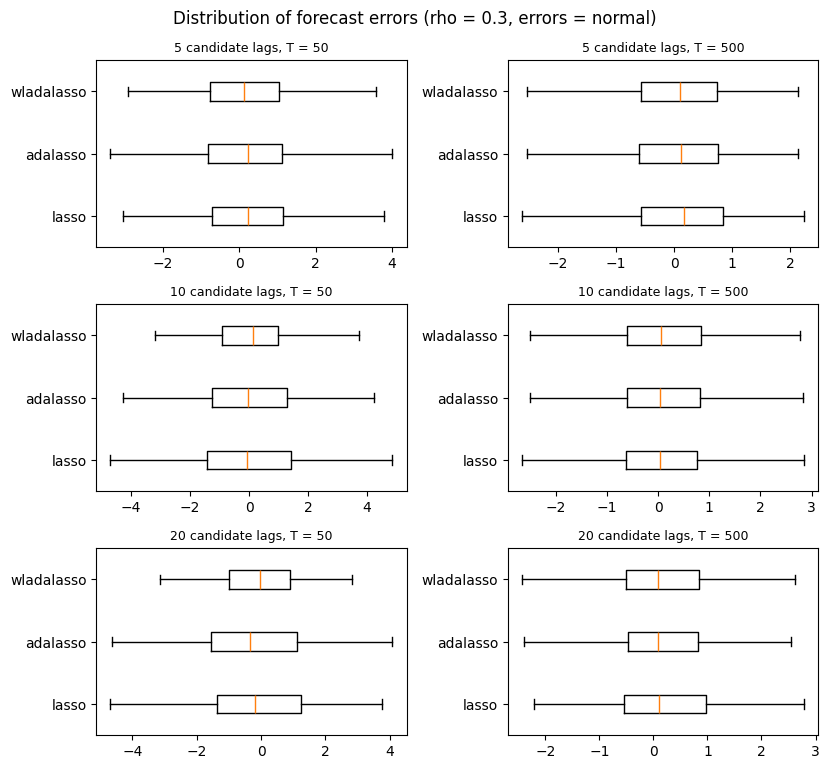

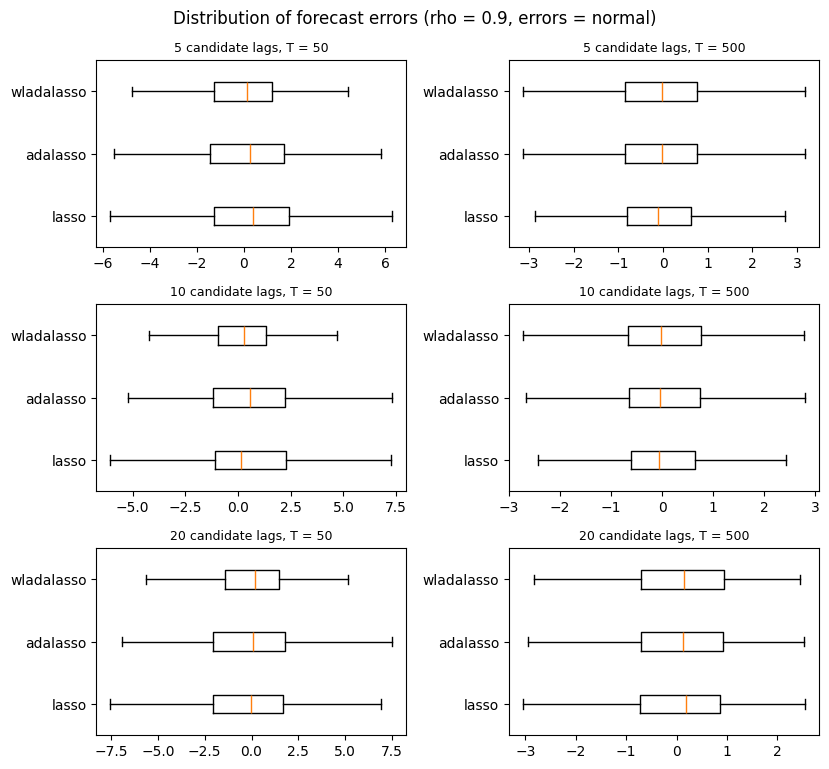

In [54]:
def plot_forecast_error_figure(rho, err="normal"):
    Ls, Ts = SIM["L_list"], SIM["T_list"]
    fig, axes = plt.subplots(len(Ls), len(Ts), figsize=(4.2 * len(Ts), 2.6 * len(Ls)), squeeze=False)
    for i, L in enumerate(Ls):
        for j, T in enumerate(Ts):
            reps = all_reps.get((err, rho, L, T))
            if reps is None:
                continue
            data = [np.concatenate([r[m]["err"] for r in reps]) for m in SIM_METHODS]
            axes[i, j].boxplot(data, vert=False, showfliers=False)
            axes[i, j].set_yticklabels(SIM_METHODS)
            axes[i, j].set_title(f"{L} candidate lags, T = {T}", fontsize=9)
    fig.suptitle(f"Distribution of forecast errors (rho = {rho}, errors = {err})")
    fig.tight_layout()
    fig.savefig(OUT_DIR / f"fig_forecast_errors_rho{rho}_{err}_{TAG}.png", dpi=130)
    plt.show()

for rho in SIM["rho_list"]:
    plot_forecast_error_figure(rho)

## Extra: which alpha does BIC pick?
Useful sanity check: when predictors are persistent and L is large, WLadaLASSO should pick a clearly positive alpha.

In [55]:
alpha_rows = []
for (err, rho, L, T), reps in all_reps.items():
    a = np.array([r["wladalasso"]["alpha"] for r in reps])
    alpha_rows.append(dict(err=err, rho=rho, L=L, T=T, alpha_mean=a.mean(), alpha_median=np.median(a)))
display(pd.DataFrame(alpha_rows).pivot_table(index=["err", "rho"], columns=["L", "T"], values="alpha_median"))

L            5          10         20     
T           50   500   50   500   50   500
err    rho                                
normal 0.3  0.5  0.5  0.75  0.5  2.25  1.0
       0.9  0.5  0.0  1.00  0.5  0.50  0.5

In [57]:
%pip install -q --upgrade openpyxl

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 250.9/250.9 kB 7.9 MB/s eta 0:00:00


# Part 4: Equity-premium forecasting (paper Table X)

* Data: Goyal-Welch annual data, 14 predictors (d/p, d/y, e/p, d/e in logs, svar, b/m, ntis, tbl, lty, ltr, tms, dfy, dfr, infl), 1927-2005.
* Target: equity premium (log return minus log risk-free by default).
* Benchmark: expanding historical mean. Metrics: $R^2_{OS}$ (Campbell-Thompson) and the one-sided modified Diebold-Mariano p-value vs the historical mean.
* Methods: individual OLS regressions on $x_{t-1}$, OLS on all 14, LASSO/adaLASSO with $l=1$, and LASSO/adaLASSO/WLadaLASSO with the number of lags chosen by BIC (max 5).
  (With $l=1$ all lag orders are equal, so WLadaLASSO = adaLASSO and the paper does not report it.)

**Caveats**
* The paper says the series are "differentiated and centered". We difference the *predictors* (`EQ['diff_predictors']`) and centre inside every fit.
  If your numbers differ from the paper, try `diff_predictors=False`.
* Your Goyal-Welch file is a newer vintage than the paper's (data revisions), so expect small differences even in 1927-2005.

In [58]:
def load_goyal_welch(cfg):
    raw = pd.read_excel(cfg["xlsx"], sheet_name=cfg["sheet"])
    raw.columns = [str(c).strip() for c in raw.columns]
    low = {c.lower(): c for c in raw.columns}

    def col(*names):
        for nm in names:
            if nm.lower() in low:
                return pd.to_numeric(raw[low[nm.lower()]], errors="coerce")
        raise KeyError(f"None of {names} found. Columns available: {list(raw.columns)}")

    year = col("yyyy", "year").round().astype("Int64")
    idx, d12, e12 = col("Index"), col("D12"), col("E12")
    rf = col("Rfree")
    if "crsp_spvw" in low:
        ret = col("CRSP_SPvw")
    else:
        ret = (idx + d12) / idx.shift(1) - 1
    eqp = (np.log1p(ret) - np.log1p(rf)) if cfg["log_premium"] else (ret - rf)

    X = pd.DataFrame({
        "d/p": np.log(d12) - np.log(idx),
        "d/y": np.log(d12) - np.log(idx.shift(1)),
        "e/p": np.log(e12) - np.log(idx),
        "d/e": np.log(d12) - np.log(e12),
        "svar": col("svar"),
        "b/m": col("b/m"),
        "ntis": col("ntis"),
        "tbl": col("tbl"),
        "lty": col("lty"),
        "ltr": col("ltr"),
        "tms": col("lty") - col("tbl"),
        "dfy": col("BAA") - col("AAA"),
        "dfr": col("corpr") - col("ltr"),
        "infl": col("infl"),
    })
    df = pd.concat([eqp.rename("eqp"), X], axis=1)
    ok = year.notna().values
    df = df[ok]
    df.index = year[ok].astype(int).values
    df = df.loc[cfg["start_year"]:cfg["end_year"]]
    if cfg["diff_predictors"]:
        df[X.columns] = df[X.columns].diff()
    n0 = len(df)
    df = df.dropna()
    if len(df) < n0 - 1:
        print(f"WARNING: dropped {n0 - len(df)} rows with missing values")
    return df


eq_df = load_goyal_welch(EQ)
print(eq_df.shape, eq_df.index.min(), "-", eq_df.index.max())
eq_df.head()

(78, 15) 1928 - 2005


,eqp,d/p,d/y,e/p,d/e,svar,b/m,ntis,tbl,lty,ltr,tms,dfy,dfr,infl
1928,0.291033,-0.222384,-0.170508,-0.103506,-0.118878,0.010380,-0.115022,-0.013402,0.0109,0.0024,-0.088621,-0.0085,0.0013,0.042597,0.011038
1929,-0.137838,0.258867,-0.189170,0.280958,-0.022091,0.104815,0.078791,0.100454,-0.0123,0.0000,0.033272,0.0123,0.0029,-0.028954,0.017409
1930,-0.329230,0.345517,0.137064,-0.171433,0.516950,-0.057965,0.216288,-0.049636,-0.0155,-0.0010,0.012330,0.0145,0.0091,0.034691,-0.069801
1931,-0.617070,0.457885,0.157013,0.172297,0.285589,0.092754,0.615986,-0.126808,0.0093,0.0077,-0.099587,-0.0016,0.0291,0.001326,-0.029214
1932,-0.105652,-0.330437,0.141437,-0.233043,-0.097394,0.148049,0.271353,0.007889,-0.0237,-0.0092,0.221609,0.0145,-0.0127,-0.094897,-0.009572


In [59]:
def run_equity_table(df, cfg):
    D = df.values
    years = df.index.values
    names = list(df.columns[1:])
    Lfree = list(range(1, cfg["Lmax"] + 1))
    out = {}
    for s in cfg["starts"]:
        test_idx = np.flatnonzero(years >= s)
        actual = D[test_idx, 0]
        bench = np.array([D[:t, 0].mean() for t in test_idx])
        res = {}

        def score(label, pred):
            r2 = r2_oos(actual, pred, bench)
            _, p = mdm_test((actual - bench) ** 2, (actual - pred) ** 2)
            res[label] = (r2, p)

        for j, nm in enumerate(names):
            score(nm, ols_forecast(D, test_idx, [1 + j]))
        score("All regressors", ols_forecast(D, test_idx, list(range(1, D.shape[1]))))
        for m in ["lasso", "adalasso"]:
            fc = rolling_forecast(D, test_idx, m, [1], t0=1, drop_own=True, n_jobs=N_JOBS)
            score(f"{m} (l=1)", fc["pred"])
        for m in ["lasso", "adalasso", "wladalasso"]:
            fc = rolling_forecast(D, test_idx, m, Lfree, t0=cfg["Lmax"], drop_own=True, n_jobs=N_JOBS)
            score(f"{m} (free l)", fc["pred"])
        out[s] = res
    return out

eq_res = cached(f"equity_{TAG}_diff{EQ['diff_predictors']}", lambda: run_equity_table(eq_df, EQ))

rows = {}
for s, res in eq_res.items():
    for label, (r2, p) in res.items():
        rows.setdefault(label, {})[(f"from {s}", "R2_OS")] = r2
        rows[label][(f"from {s}", "MDM p")] = p
TABLE_X = pd.DataFrame(rows).T
TABLE_X.columns = pd.MultiIndex.from_tuples(TABLE_X.columns)
TABLE_X.to_csv(OUT_DIR / f"table_X_equity_{TAG}.csv")
print("Table X: equity premium forecasting (R2_OS vs expanding historical mean)")
display(TABLE_X.round(4))

[cached] equity_fast_diffTrue done in 49.2s
Table X: equity premium forecasting (R2_OS vs expanding historical mean)


from 1955         from 1970         from 1985        
                        R2_OS   MDM p     R2_OS   MDM p     R2_OS   MDM p
d/p                   -0.0488  0.8051   -0.0233  0.6384   -0.0228  0.6549
d/y                   -0.0016  0.5265    0.0216  0.2314   -0.0341  0.7481
e/p                   -0.0104  0.7850   -0.0133  0.8061    0.0017  0.4610
d/e                   -0.0867  0.7815   -0.0721  0.6917    0.1299  0.2876
svar                  -0.0004  0.5175   -0.0006  0.5280   -0.0114  0.8422
b/m                   -0.0067  0.6881   -0.0031  0.5863   -0.0016  0.5501
ntis                  -0.0137  0.8066   -0.0153  0.7706   -0.0383  0.9333
tbl                   -0.0321  0.6159   -0.0668  0.6724   -0.2438  0.9124
lty                   -0.0252  0.5718   -0.1201  0.7409   -0.1903  0.9358
ltr                   -0.0294  0.6083   -0.1030  0.7872   -0.2536  0.8871
tms                   -0.0730  0.8594   -0.0639  0.7559   -0.1669  0.8878
dfy                   -0.1102  0.9673   -0.0973  0.9437   -0.0123  0.6106
dfr                   -0.0053  0.5459   -0.0071  0.5473   -0.0357  0.6653
infl                  -0.0203  0.9348   -0.0148  0.8344   -0.0046  0.6458
All regressors        -0.3952  0.9779   -0.2417  0.8652   -0.2985  0.7929
lasso (l=1)           -0.0181  0.8486    0.0043  0.3229   -0.0079  0.7746
adalasso (l=1)        -0.0661  0.9509   -0.0340  0.8747    0.0003  0.4935
lasso (free l)        -0.2377  0.9355   -0.0514  0.7171    0.0201  0.3725
adalasso (free l)     -0.2813  0.9671   -0.1421  0.8480   -0.0347  0.6847
wladalasso (free l)   -0.2766  0.9636   -0.1431  0.8489   -0.0341  0.6810

# Part 5: FRED-MD loader

Steps (McCracken & Ng, 2016): read levels, read the transformation codes from the first data row (`Transform:`),
apply the codes, flag outliers (more than 10 interquartile ranges from the median) as missing, keep a balanced panel
(drop series with more than 5% missing after the start date) and forward/backward fill the rest.

t-codes: 1 level, 2 diff, 3 second diff, 4 log, 5 diff log, 6 second diff log, 7 diff of percentage change.

In [60]:
def tcode_transform(x, code):
    x = x.astype(float)
    if code == 1: return x
    if code == 2: return x.diff()
    if code == 3: return x.diff().diff()
    if code == 4: return np.log(x)
    if code == 5: return np.log(x).diff()
    if code == 6: return np.log(x).diff().diff()
    if code == 7: return (x / x.shift(1) - 1.0).diff()
    raise ValueError(f"unknown tcode {code}")


def load_fred_md(csv_path, start="1960-03-01", end=None, max_missing=0.05, outlier_iqr=10.0):
    raw = pd.read_csv(csv_path)
    date_col = raw.columns[0]
    tcodes = raw.iloc[0, 1:].astype(float)                 # 'Transform:' row
    dat = raw.iloc[1:].copy()
    dat[date_col] = pd.to_datetime(dat[date_col], errors="coerce")
    dat = dat.dropna(subset=[date_col]).set_index(date_col)
    dat = dat.apply(pd.to_numeric, errors="coerce")
    dat.index.name = "date"

    X = pd.DataFrame({c: tcode_transform(dat[c], int(tcodes[c])) for c in dat.columns})
    X = X.replace([np.inf, -np.inf], np.nan)

    # outliers -> NaN (per series, using the post-transformation values)
    med = X.median()
    iqr = X.quantile(0.75) - X.quantile(0.25)
    X = X.mask((X - med).abs() > outlier_iqr * iqr)

    X = X.loc[start:end] if end else X.loc[start:]
    keep = X.columns[X.isna().mean() <= max_missing]
    dropped = [c for c in X.columns if c not in keep]
    X = X[keep].ffill().bfill()
    print(f"FRED-MD: {X.shape[0]} months x {X.shape[1]} series "
          f"({X.index.min():%Y-%m} to {X.index.max():%Y-%m}); dropped {len(dropped)} series with too many gaps")
    return X, dat, tcodes


def load_groups(appendix_path, columns):
    """Map every FRED-MD series to its group id (1..8) using the official appendix csv. Returns Series or None."""
    try:
        app = pd.read_csv(appendix_path, encoding="latin-1")
        app.columns = [str(c).strip().lower() for c in app.columns]
        name_col = next(c for c in app.columns if "fred" in c)
        grp_col = next(c for c in app.columns if "group" in c)
        mp = dict(zip(app[name_col].astype(str).str.strip(), app[grp_col]))
        g = pd.Series({c: mp.get(c, np.nan) for c in columns})
        if g.isna().mean() > 0.5:
            raise ValueError("less than half of the series matched the appendix")
        codes, uniques = pd.factorize(g.fillna("other"))
        print(f"Groups loaded from appendix: {len(uniques)} groups; unmatched series -> 'other'")
        return pd.Series(codes + 1, index=columns), list(uniques)
    except Exception as e:
        print("WARNING: could not read FRED-MD appendix groups (", e, "). Ext2 will use own-lags vs other variables.")
        return None, None


X_md, LEVELS_md, TCODES_md = load_fred_md(FRED["csv"], start=FRED["start"], end=FRED["end"])
GROUPS_md, GROUP_NAMES_md = load_groups(FRED["appendix"], X_md.columns)
X_md.iloc[:3, :8]

FRED-MD: 791 months x 122 series (1960-03 to 2026-01); dropped 4 series with too many gaps
Groups loaded from appendix: 9 groups; unmatched series -> 'other'


,RPI,W875RX1,DPCERA3M086SBEA,CMRMTSPLx,RETAILx,INDPRO,IPFPNSS,IPFINAL
date,,,,,,,,
1960-03-01,0.001877,0.000905,0.014089,-0.028040,-0.001102,-0.009018,-0.003427,-0.001148
1960-04-01,0.003465,0.003612,0.015302,0.009853,0.025903,-0.007959,0.002286,0.001148
1960-05-01,0.002405,0.002427,-0.020351,-0.031518,-0.015047,-0.001141,0.005692,0.006867


# Part 6: Quarterly inflation forecasting (paper Table XI analogue, built from FRED-MD)

**What differs from the paper (be explicit about this in your write-up)**
* The paper uses 16 predictors from Groen, Paap & Ravazzolo (2013), which are not publicly packaged. Following our commitment to FRED-MD,
  we pick up to 16 FRED-MD series covering the same categories (real activity, term structure, nominal, prices) and aggregate them to
  quarterly frequency (average of the transformed monthly values). The target is quarterly PCE-deflator inflation
  $\pi_t = 400\,\Delta\log P_t$ (PCEPI from FRED-MD levels), modelled in differences $\Delta\pi_t$ (errors for $\pi_t$ are identical).
* The paper benchmarks against Chan's UC-MA stochastic-volatility model (MCMC). Re-implementing it is outside the scope of this notebook, so we use
  two transparent benchmarks instead: **UC-lite** (a local-level exponential smoother with the gain chosen recursively by in-sample SSE,
  a rough stand-in for unobserved-components models) and **AR(p)** with p chosen by BIC. Do **not** report these as UC-MA results.
* Two evaluation windows of 20 quarters each (the last 20 observations and the 20 before), sample ending 2011Q2 as in the paper.
* Number of lags chosen by BIC over `INF['Lgrid']` (the paper uses up to 20).

In [61]:
INF_CANDS = ["INDPRO", "UNRATE", "PAYEMS", "CUMFNS", "HOUST", "DPCERA3M086SBEA",       # real activity
             "TB3MS", "GS1", "GS10", "T10YFFM", "TB3SMFFM", "AAAFFM",                   # term structure / spreads
             "CPIAUCSL", "WPSFD49207", "PPICMM", "M2SL", "OILPRICEx", "AHETPIx", "S&P 500"]   # nominal / prices / asset

def build_quarterly_panel(levels, X, cfg):
    price = cfg["price"] if cfg["price"] in levels.columns else "CPIAUCSL"
    if price != cfg["price"]:
        print(f"WARNING: {cfg['price']} not in this FRED-MD vintage; using {price}")
    p = levels[price].dropna()
    p_q = p.groupby(p.index.to_period("Q")).mean()
    pi = 400 * np.log(p_q).diff()
    dpi = pi.diff().rename("dpi")
    avail = [c for c in INF_CANDS if c in X.columns and c != price][:cfg["n_pred"]]
    Xq = X[avail].groupby(X.index.to_period("Q")).mean()
    df = pd.concat([dpi, Xq], axis=1).dropna()
    df = df[df.index <= pd.Period(cfg["end"], "Q")]
    print(f"Quarterly panel: {df.shape[0]} quarters ({df.index.min()} to {df.index.max()}), predictors: {avail}")
    return df, pi.loc[df.index]

qdf, qpi = build_quarterly_panel(LEVELS_md, X_md, INF)

Quarterly panel: 206 quarters (1960Q1 to 2011Q2), predictors: ['INDPRO', 'UNRATE', 'PAYEMS', 'CUMFNS', 'HOUST', 'DPCERA3M086SBEA', 'TB3MS', 'GS1', 'GS10', 'T10YFFM', 'TB3SMFFM', 'AAAFFM', 'CPIAUCSL', 'WPSFD49207', 'PPICMM', 'M2SL']


In [62]:
def ewma_forecasts(pi, test_idx, gains=np.linspace(0.05, 0.95, 19)):
    """UC-lite: local-level smoother, gain chosen at each origin by in-sample one-step SSE."""
    out = []
    for t in test_idx:
        hist = pi[:t]
        best = None
        for g in gains:
            s, sse = hist[0], 0.0
            for x in hist[1:]:
                sse += (x - s) ** 2
                s = s + g * (x - s)
            if best is None or sse < best[0]:
                best = (sse, s)
        out.append(best[1])
    return np.array(out)


def run_inflation(df, pi, cfg):
    D, pi_v = df.values, pi.values
    n = len(D)
    Lgrid = cfg["Lgrid"]
    t0 = max(Lgrid)
    k = cfg["period_len"]
    periods = {"Penultimate period": np.arange(n - 2 * k, n - k), "Last period": np.arange(n - k, n)}
    out = {}
    for name, test_idx in periods.items():
        errs = {}
        errs["UC-lite (EWMA)"] = pi_v[test_idx] - ewma_forecasts(pi_v, test_idx)
        errs["AR(BIC)"] = D[test_idx, 0] - ar_forecasts(D[:, 0], test_idx, pmax=8)
        for m in ["lasso", "adalasso", "wladalasso"]:
            fc = rolling_forecast(D, test_idx, m, Lgrid, t0=t0, refit_every=cfg["refit_every"], n_jobs=N_JOBS)
            errs[m] = fc["actual"] - fc["pred"]
        out[name] = errs
    return out

inf_errs = cached(f"inflation_{TAG}", lambda: run_inflation(qdf, qpi, INF))

rows = []
for period, errs in inf_errs.items():
    b = errs["UC-lite (EWMA)"]
    for m, e in errs.items():
        p_mse = np.nan if m == "UC-lite (EWMA)" else mdm_test(b ** 2, e ** 2)[1]
        p_mae = np.nan if m == "UC-lite (EWMA)" else mdm_test(np.abs(b), np.abs(e))[1]
        rows.append(dict(period=period, model=m, MSE=np.mean(e ** 2), MSE_MDM_p=p_mse,
                         MAE=np.mean(np.abs(e)), MAE_MDM_p=p_mae))
TABLE_XI = pd.DataFrame(rows)
TABLE_XI.to_csv(OUT_DIR / f"table_XI_inflation_{TAG}.csv", index=False)
print("Table XI analogue (MDM p-values are against UC-lite; small p = better than the benchmark)")
display(TABLE_XI.round(4))

[cached] inflation_fast done in 4.3s
Table XI analogue (MDM p-values are against UC-lite; small p = better than the benchmark)


,period,model,MSE,MSE_MDM_p,MAE,MAE_MDM_p
0,Penultimate period,UC-lite (EWMA),1.4039,NaN,0.9548,NaN
1,Penultimate period,AR(BIC),1.3971,0.4510,0.9548,0.5012
2,Penultimate period,lasso,2.1733,0.9382,1.2295,0.9602
3,Penultimate period,adalasso,2.3056,0.9448,1.2360,0.9499
4,Penultimate period,wladalasso,2.3056,0.9448,1.2360,0.9499
5,Last period,UC-lite (EWMA),8.6466,NaN,1.8921,NaN
6,Last period,AR(BIC),8.5858,0.4610,1.8841,0.4679
7,Last period,lasso,6.7394,0.2196,1.8245,0.3951
8,Last period,adalasso,6.5177,0.1990,1.7840,0.3332
9,Last period,wladalasso,6.3389,0.1928,1.7486,0.2831


# Part 7: Extensions on FRED-MD (monthly inflation forecasting)

**Setup**
* Target: $\Delta\pi_t$ where $\pi_t = 1200\,\Delta\log(\text{CPIAUCSL})$ (this is the FRED-MD t-code-6 variable, rescaled; forecast errors for
  $\pi_t$ are identical because $\hat\pi_t=\pi_{t-1}+\widehat{\Delta\pi}_t$).
* Predictors: all other transformed FRED-MD series plus own lags, $L=12$ candidate lags each (roughly 1,300 candidate regressors vs. about 700 observations).
* Rolling expanding-window one-step-ahead forecasts over the last `FRED['n_test']` months, refit every `FRED['refit_every']` months.
* Benchmark: AR(p), p chosen by BIC (p = 0 is the historical mean).

**Methods compared**
| name | penalty weight |
|---|---|
| lasso | 1 |
| adalasso | $1/|\hat\beta^{ridge}|$ |
| adalasso_g | $1/|\hat\beta^{ridge}|^{\gamma}$, $\gamma$ by BIC (**ablation**: is WLadaLASSO's gain just one more tuned parameter?) |
| wladalasso | adaLASSO $\times\,e^{\alpha l}$ (paper) |
| ext1 | adaLASSO $\times\,(m(1)/m(l))^{\kappa}$, $m$ = isotonic lag profile learned from the data (**our Extension 1**) |
| ext2 | adaLASSO $\times\,e^{\alpha_{g(j)} l}$, one $\alpha$ per variable group: own lags + the FRED-MD groups (**our Extension 2**) |

In [63]:
def build_monthly_panel(levels, X, cfg):
    tgt = cfg["target"]
    p = levels[tgt].dropna()
    pi_m = 1200 * np.log(p).diff()
    dpi = pi_m.diff().rename("dpi")
    Xp = X.drop(columns=[tgt], errors="ignore")
    df = pd.concat([dpi, Xp], axis=1).dropna()
    return df, pi_m.loc[df.index]

md_df, md_pi = build_monthly_panel(LEVELS_md, X_md, FRED)
D_md = md_df.values
dates_md = md_df.index
n_md = len(D_md)
test_idx_md = np.arange(n_md - FRED["n_test"], n_md)
M_md = D_md.shape[1]

# variable groups: 0 = own lags of the target; FRED-MD groups afterwards (fallback: 1 = everything else)
if GROUPS_md is not None:
    var_groups_md = np.array([0] + [int(GROUPS_md.get(c, GROUPS_md.max() + 1)) for c in md_df.columns[1:]])
else:
    var_groups_md = np.array([0] + [1] * (M_md - 1))
L_md = FRED["L"]
print(f"Panel: {n_md} months, {M_md - 1} predictors x {L_md} lags (+ own lags) = {M_md * L_md} candidates")
print(f"Test window: {dates_md[test_idx_md[0]]:%Y-%m} to {dates_md[test_idx_md[-1]]:%Y-%m}  ({len(test_idx_md)} months)")
print("Variables per group:", dict(pd.Series(var_groups_md).value_counts().sort_index()))

Panel: 790 months, 121 predictors x 12 lags (+ own lags) = 1464 candidates
Test window: 2021-01 to 2026-01  (60 months)
Variables per group: {0: np.int64(1), 1: np.int64(15), 2: np.int64(7), 3: np.int64(1), 4: np.int64(31), 5: np.int64(10), 6: np.int64(13), 7: np.int64(4), 8: np.int64(21), 9: np.int64(19)}


## Run all methods (each is cached separately, so a crash never loses finished methods)
The expensive ones are `ext2` (about 40-60 path fits per refit) and `wladalasso`. Lower `FRED['L']`, `FRED['n_test']`, or raise `FRED['refit_every']` to speed up.

In [64]:
FRED_METHODS = ["lasso", "adalasso", "adalasso_g", "wladalasso", "ext1", "ext2"]

def run_fred(method):
    return rolling_forecast(D_md, test_idx_md, method, [L_md], t0=L_md, refit_every=FRED["refit_every"],
                            var_groups=var_groups_md, cfg=FRED_FIT, n_jobs=N_JOBS)

fred_res = {}
for m in FRED_METHODS:
    t_ = time.time()
    fred_res[m] = cached(f"fred_{TAG}_{m}", lambda m=m: run_fred(m))
    print(f"{m:11s} ready ({time.time() - t_:.0f}s)")

ar_pred = cached(f"fred_{TAG}_AR", lambda: ar_forecasts(D_md[:, 0], test_idx_md, pmax=12))
actual_md = D_md[test_idx_md, 0]
ERR_md = {"AR(BIC)": actual_md - ar_pred}
for m, r in fred_res.items():
    ERR_md[m] = r["actual"] - r["pred"]

[cached] fred_fast_lasso done in 29.2s
lasso       ready (29s)
[cached] fred_fast_adalasso done in 9.1s
adalasso    ready (9s)
[cached] fred_fast_adalasso_g done in 25.2s
adalasso_g  ready (25s)
[cached] fred_fast_wladalasso done in 29.9s
wladalasso  ready (30s)
[cached] fred_fast_ext1 done in 24.2s
ext1        ready (24s)
[cached] fred_fast_ext2 done in 344.4s
ext2        ready (344s)
[cached] fred_fast_AR done in 0.1s


## Accuracy table
`relRMSE` and `relMAE` are relative to the AR(BIC) benchmark (below 1 = better). `p(MSE)` / `p(MAE)` are one-sided modified Diebold-Mariano p-values
against AR(BIC). The second table drops the COVID window (2020-03 to 2021-12), which can dominate squared errors.

In [65]:
def accuracy_table(ERR, mask=None, bench="AR(BIC)"):
    rows = []
    mk = np.ones(len(ERR[bench]), bool) if mask is None else mask
    eb = ERR[bench][mk]
    for m, e in ERR.items():
        e = e[mk]
        rows.append(dict(model=m, RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)),
                         relRMSE=np.sqrt(np.mean(e ** 2) / np.mean(eb ** 2)),
                         relMAE=np.mean(np.abs(e)) / np.mean(np.abs(eb)),
                         **({} if m == bench else dict(
                             p_MSE=mdm_test(eb ** 2, e ** 2)[1], p_MAE=mdm_test(np.abs(eb), np.abs(e))[1]))))
    return pd.DataFrame(rows).set_index("model")

dts = dates_md[test_idx_md]
covid = (dts >= "2020-03-01") & (dts <= "2021-12-31")
ACC_full = accuracy_table(ERR_md)
ACC_ex = accuracy_table(ERR_md, mask=~covid) if covid.any() else None
print("All test months"); display(ACC_full.round(4))
if ACC_ex is not None:
    print("Excluding 2020-03 to 2021-12"); display(ACC_ex.round(4))
ACC_full.to_csv(OUT_DIR / f"fred_accuracy_full_{TAG}.csv")
if ACC_ex is not None:
    ACC_ex.to_csv(OUT_DIR / f"fred_accuracy_ex_covid_{TAG}.csv")

All test months


,RMSE,MAE,relRMSE,relMAE,p_MSE,p_MAE
model,,,,,,
AR(BIC),2.8893,1.9914,1.0000,1.0000,NaN,NaN
lasso,2.9993,2.0030,1.0381,1.0058,0.7221,0.5261
adalasso,2.9056,1.9671,1.0056,0.9878,0.5348,0.4458
adalasso_g,2.8806,1.9392,0.9970,0.9737,0.4828,0.3873
wladalasso,2.9183,1.9739,1.0100,0.9912,0.5611,0.4618
ext1,2.9167,1.9839,1.0095,0.9962,0.5574,0.4835
ext2,2.9362,2.0236,1.0162,1.0161,0.6025,0.5723


Excluding 2020-03 to 2021-12


,RMSE,MAE,relRMSE,relMAE,p_MSE,p_MAE
model,,,,,,
AR(BIC),2.9541,1.9575,1.0000,1.0000,NaN,NaN
lasso,3.1558,2.0744,1.0683,1.0597,0.8337,0.7300
adalasso,3.0548,2.0496,1.0341,1.0470,0.6865,0.6839
adalasso_g,3.0236,2.0085,1.0235,1.0260,0.6193,0.6010
wladalasso,3.0592,2.0307,1.0356,1.0374,0.6941,0.6451
ext1,3.0551,2.0410,1.0342,1.0427,0.6869,0.6655
ext2,3.0944,2.1147,1.0475,1.0803,0.7615,0.8000


## Pairwise tests: do the extensions beat the paper's WLadaLASSO and the ablation?

In [66]:
pairs = [("ext1", "wladalasso"), ("ext2", "wladalasso"), ("ext2", "ext1"),
         ("wladalasso", "adalasso"), ("wladalasso", "adalasso_g"), ("ext1", "adalasso_g"), ("ext2", "adalasso_g")]
rows = []
for a, b in pairs:
    rows.append(dict(better="'" + a + "'", than="'" + b + "'",
                     MSE_ratio=np.mean(ERR_md[a] ** 2) / np.mean(ERR_md[b] ** 2),
                     p_MSE=mdm_test(ERR_md[b] ** 2, ERR_md[a] ** 2)[1],
                     p_MAE=mdm_test(np.abs(ERR_md[b]), np.abs(ERR_md[a]))[1]))
PAIR_md = pd.DataFrame(rows)
display(PAIR_md.round(4))
PAIR_md.to_csv(OUT_DIR / f"fred_pairwise_{TAG}.csv", index=False)

,better,than,MSE_ratio,p_MSE,p_MAE
0,'ext1','wladalasso',0.9989,0.4599,0.7462
1,'ext2','wladalasso',1.0123,0.7767,0.9490
2,'ext2','ext1',1.0134,0.7479,0.8993
3,'wladalasso','adalasso',1.0088,0.7021,0.6066
4,'wladalasso','adalasso_g',1.0264,0.7856,0.8131
5,'ext1','adalasso_g',1.0252,0.8333,0.9055
6,'ext2','adalasso_g',1.0390,0.8437,0.9760


# Part 8: Diagnostics for the extensions
1. Cumulative squared-error gain over the AR benchmark (is the gain persistent or driven by a few months?).
2. Which lags does each method actually select?
3. Ext1: the lag profile learned from the data (versus the exponential profile imposed by the paper).
4. Ext2: the group-specific decay rates the data asks for.
5. Sparsity and chosen hyper-parameters.

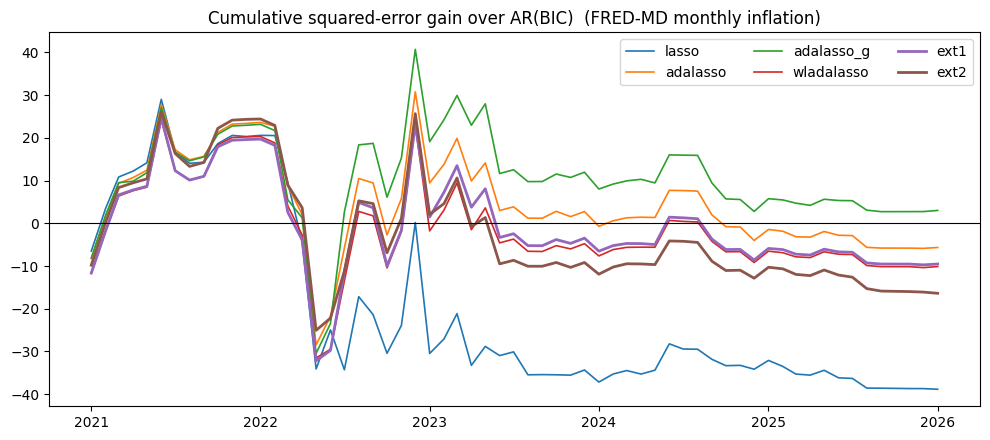

In [67]:
# 1. Cumulative squared forecast error difference vs AR(BIC): rising line = method beats the benchmark.
fig, ax = plt.subplots(figsize=(10, 4.5))
for m in FRED_METHODS:
    gain = np.cumsum(ERR_md["AR(BIC)"] ** 2 - ERR_md[m] ** 2)
    ax.plot(dts, gain, label=m, lw=2 if m in ("ext1", "ext2") else 1.2)
ax.axhline(0, color="k", lw=0.8)
ax.set_title("Cumulative squared-error gain over AR(BIC)  (FRED-MD monthly inflation)")
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_fred_cumulative_gain_{TAG}.png", dpi=130)
plt.show()

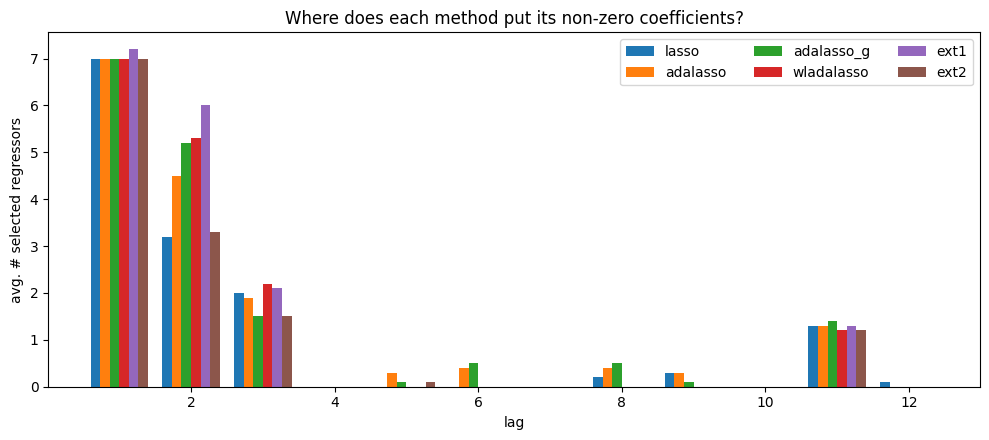

In [68]:
# 2. Selected lags per method (average number of selected regressors at each lag, across refits)
def lag_profile_of_fits(res, L):
    lag_order, var_id = res["designs_meta"][L]
    mat = np.array([[np.sum(f["coef"][lag_order == l] != 0) for l in range(1, L + 1)] for f in res["fits"].values()])
    return mat.mean(0)

fig, ax = plt.subplots(figsize=(10, 4.5))
w = 0.8 / len(FRED_METHODS)
for i, m in enumerate(FRED_METHODS):
    prof = lag_profile_of_fits(fred_res[m], L_md)
    ax.bar(np.arange(1, L_md + 1) + (i - len(FRED_METHODS) / 2) * w + w / 2, prof, width=w, label=m)
ax.set_xlabel("lag"); ax.set_ylabel("avg. # selected regressors")
ax.set_title("Where does each method put its non-zero coefficients?")
ax.legend(ncol=3)
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_fred_selected_lags_{TAG}.png", dpi=130)
plt.show()

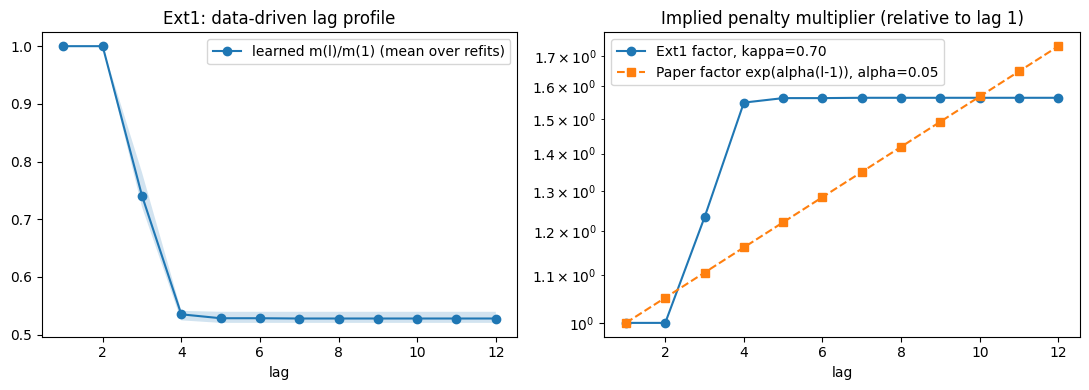

kappa chosen over refits: {0.5: 6, 1.0: 4}
alpha chosen by WLadaLASSO: {0.0: 1, 0.05: 8, 0.1: 1}


In [69]:
# 3. Ext1: learned lag profile m(l)/m(1) (average over refits) and the penalty factor it implies.
profiles = np.array([f["hyper"]["profile"] for f in fred_res["ext1"]["fits"].values()])
kappas = np.array([f["hyper"]["kappa"] for f in fred_res["ext1"]["fits"].values()])
alphas_wl = np.array([f["hyper"]["alpha"] for f in fred_res["wladalasso"]["fits"].values()])
lags = np.arange(1, L_md + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(lags, profiles.mean(0), "o-", label="learned m(l)/m(1) (mean over refits)")
axes[0].fill_between(lags, profiles.min(0), profiles.max(0), alpha=0.2)
axes[0].set_xlabel("lag"); axes[0].set_title("Ext1: data-driven lag profile"); axes[0].legend()
kappa_mean = kappas.mean()
axes[1].plot(lags, (1 / profiles.mean(0)) ** kappa_mean, "o-", label=f"Ext1 factor, kappa={kappa_mean:.2f}")
axes[1].plot(lags, np.exp(alphas_wl.mean() * (lags - 1)), "s--", label=f"Paper factor exp(alpha(l-1)), alpha={alphas_wl.mean():.2f}")
axes[1].set_yscale("log"); axes[1].set_xlabel("lag"); axes[1].set_title("Implied penalty multiplier (relative to lag 1)")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_fred_ext1_profile_{TAG}.png", dpi=130)
plt.show()
print("kappa chosen over refits:", pd.Series(kappas).value_counts().sort_index().to_dict())
print("alpha chosen by WLadaLASSO:", pd.Series(alphas_wl).value_counts().sort_index().to_dict())

Average common alpha (step 1 of Ext2): 0.050


,group,n_variables,alpha_mean,alpha_min,alpha_max
0,own lags of target,1,0.090,0.05,0.35
1,1.0,15,0.105,0.00,0.35
2,4.0,7,0.000,0.00,0.00
3,other,1,0.035,0.00,0.35
4,2.0,31,0.050,0.00,0.10
5,3.0,10,0.050,0.00,0.10
6,5.0,13,0.415,0.10,0.50
7,8.0,4,0.070,0.00,0.20
8,6.0,21,0.050,0.00,0.10
9,7.0,19,0.045,0.00,0.10


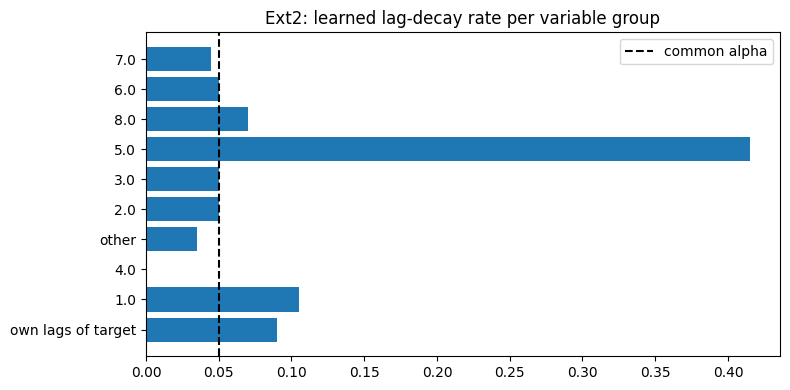

In [70]:
# 4. Ext2: group-specific decay rates
A = np.vstack([f["hyper"]["alphas"] for f in fred_res["ext2"]["fits"].values()])
common = np.array([f["hyper"]["alpha_common"] for f in fred_res["ext2"]["fits"].values()])
G = A.shape[1]
labels = ["own lags of target"] + [
    (str(GROUP_NAMES_md[g - 1]) if GROUP_NAMES_md is not None and 0 < g <= len(GROUP_NAMES_md) else f"group {g}")
    for g in range(1, G)]
GROUP_ALPHA = pd.DataFrame({"group": labels,
                            "n_variables": [int(np.sum(var_groups_md == g)) for g in range(G)],
                            "alpha_mean": A.mean(0), "alpha_min": A.min(0), "alpha_max": A.max(0)})
print(f"Average common alpha (step 1 of Ext2): {common.mean():.3f}")
display(GROUP_ALPHA.round(3))
GROUP_ALPHA.to_csv(OUT_DIR / f"fred_ext2_group_alphas_{TAG}.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(GROUP_ALPHA["group"], GROUP_ALPHA["alpha_mean"])
ax.axvline(common.mean(), color="k", ls="--", label="common alpha")
ax.set_title("Ext2: learned lag-decay rate per variable group"); ax.legend()
fig.tight_layout()
fig.savefig(OUT_DIR / f"fig_fred_ext2_group_alphas_{TAG}.png", dpi=130)
plt.show()

In [71]:
# 5. Sparsity and hyper-parameters
def mean_hyper(fits):
    out = {}
    for k in next(iter(fits))["hyper"]:
        v = [f["hyper"][k] for f in fits]
        if np.ndim(v[0]) == 0:
            out[k] = round(float(np.mean(v)), 3)
    return out

rows = []
for m in FRED_METHODS:
    fits = list(fred_res[m]["fits"].values())
    rows.append(dict(method=m, avg_nonzero=np.mean([f["df"] for f in fits]),
                     avg_BIC=np.mean([f["bic"] for f in fits]), mean_hyper=str(mean_hyper(fits))))
SPARSITY = pd.DataFrame(rows)
display(SPARSITY)

,method,avg_nonzero,avg_BIC,mean_hyper
0,lasso,14.1,1610.537585,{}
1,adalasso,16.1,1558.387440,{'gamma': 1.0}
2,adalasso_g,16.3,1547.793084,{'gamma': 2.0}
3,wladalasso,15.7,1547.435175,{'alpha': 0.05}
4,ext1,16.6,1548.475886,{'kappa': 0.7}
5,ext2,13.1,1540.653087,{'alpha_common': 0.05}


# Final summary tables (all saved in `results/`)
* `table_X_equity_*.csv`: paper Table X replication (Goyal-Welch).
* `simulation_summary_*.csv` and the printed Tables I-IX: Monte Carlo replication.
* `table_XI_inflation_*.csv`: quarterly inflation exercise built from FRED-MD (analogue of Table XI).
* `fred_accuracy_*.csv`, `fred_pairwise_*.csv`, `fred_ext2_group_alphas_*.csv` and the `fig_fred_*.png` files: extension results on FRED-MD.

**How to read the extension results honestly**
* If `ext1`/`ext2` do not beat `adalasso_g` (adaLASSO with $\gamma$ also tuned), then the gain is extra flexibility rather than the lag structure. Report it either way.
* Ext2 tunes about 9 decay parameters by BIC on a few hundred observations, so check `GROUP_ALPHA` for unstable estimates (min/max across refits).
* Rankings over a short test window are noisy; use the MDM p-values and the ex-COVID table before claiming a winner.